In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
from keras.datasets import cifar10
from keras.models import Sequential
from keras.layers import Input, Flatten, Dense
from keras.optimizers import SGD

In [4]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Test images: (10000, 32, 32, 3)
Test labels: (10000,)


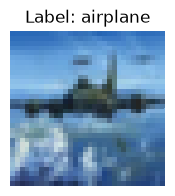

In [5]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', x_test.shape)
print('Test labels:', y_test.shape)

plt.figure(figsize=(2,3))
idx = 1205
plt.imshow(x_train[idx], interpolation='nearest')
plt.title(f'Label: {class_names[int(y_train[idx])]}')
plt.axis('off')

plt.show()

In [6]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [7]:
model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer=SGD(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=2,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.2391 - loss: 2.1323 - val_accuracy: 0.2764 - val_loss: 2.0332
Epoch 2/2
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3011 - loss: 1.9851 - val_accuracy: 0.3141 - val_loss: 1.9499


In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print('Test Loss:', test_loss)
print('Test Accuracy:', test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3141 - loss: 1.9499
Test Loss: 1.9499388933181763
Test Accuracy: 0.3140999972820282


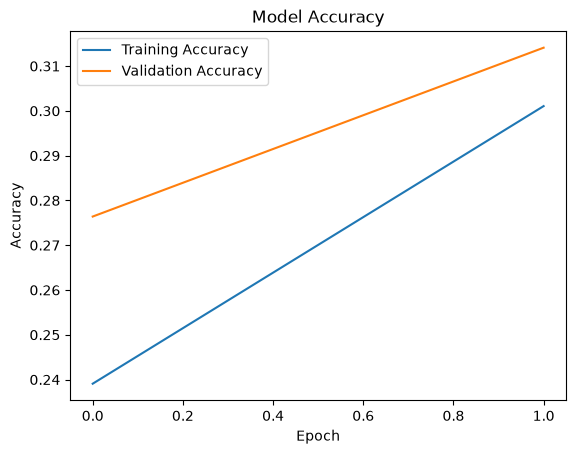

In [10]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

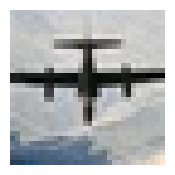

The image is classified as airplane
Actual class is airplane


In [11]:
import random

n = random.randrange(len(x_test))

plt.figure(figsize=(2,3))
plt.imshow(x_test[n])
plt.axis('off')
plt.show()

prediction = model.predict(x_test[n:n + 1], verbose=0)

predicted_class = int(np.argmax(prediction[0]))

print('The image is classified as', class_names[predicted_class])
print('Actual class is', class_names[y_test[n]])